# Assignment 03: Customer Churn Prediction with a Tuned Neural Network
**AI/ML Internship | Week 3**  
**Student:** Abdul Basit

## Objective
Build a neural network to predict whether a telecommunications customer will leave (churn), compare a baseline model with a tuned model, evaluate the best model, and save it for future predictions.

**Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)

> Run the notebook from top to bottom in Google Colab. If the CSV is not in the current session, the first data-loading cell will ask you to upload it.

In [11]:
# 1. Import libraries and set reproducible seeds
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Pandas version:", pd.__version__)

TensorFlow version: 2.21.0
Pandas version: 2.2.3


In [12]:
# 2. Load the dataset
DATA_PATH = "/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload the Telco Customer Churn CSV file.")
        DATA_PATH = csv_files[0]
    except ImportError:
        DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
        if not os.path.exists(DATA_PATH):
            raise FileNotFoundError(
                "Place WA_Fn-UseC_-Telco-Customer-Churn.csv in the notebook folder, "
                "or upload it when prompted in Google Colab."
            )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Column data types:


,data_type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


\nMissing values before cleaning:


,missing_values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


\nDuplicate rows: 0
\nChurn distribution:


,count
Churn,
No,5174
Yes,1869


,percentage
Churn,
No,73.46
Yes,26.54


\nMissing TotalCharges after numeric conversion: 11
Missing values after cleaning: 0


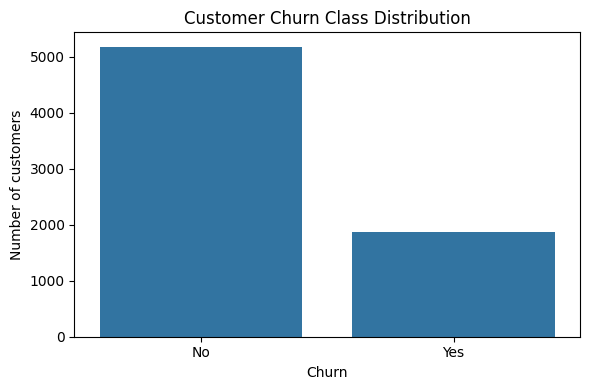

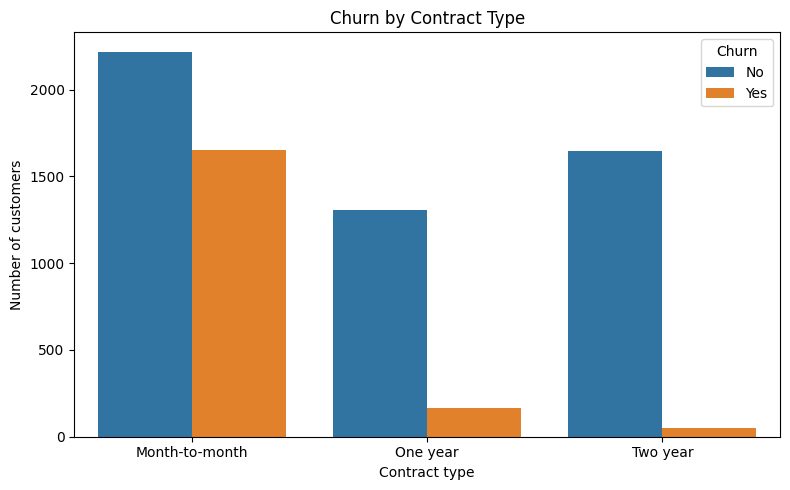

Interpretation: The churn classes are not equally represented. Contract type is useful to explore because churn rates can differ across contract groups.


In [13]:
# 3. Explore and clean the data
print("Column data types:")
display(df.dtypes.to_frame("data_type"))

print("\\nMissing values before cleaning:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nChurn distribution:")
display(df["Churn"].value_counts().to_frame("count"))
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

# TotalCharges is stored as text and includes blank strings.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
print("\\nMissing TotalCharges after numeric conversion:", df["TotalCharges"].isna().sum())

# Rows with blank TotalCharges generally have zero tenure. Impute with 0 for this field.
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing values after cleaning:", int(df.isna().sum().sum()))

# Churn class balance plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"])
plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Explore churn by contract type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn", order=["Month-to-month", "One year", "Two year"])
plt.title("Churn by Contract Type")
plt.xlabel("Contract type")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Interpretation: The churn classes are not equally represented. Contract type is useful to explore because churn rates can differ across contract groups.")


## Preprocessing choices
- `customerID` is removed because it is an identifier rather than a meaningful customer characteristic.
- `Churn` is converted to a binary target: `No = 0`, `Yes = 1`.
- Categorical predictors are one-hot encoded. This is suitable for nominal categories such as contract and payment method because it does not impose an artificial numerical order.
- Numeric predictors are standardized. The preprocessing pipeline is fitted only on the training data to reduce data leakage.
- A stratified train/test split preserves the approximate churn proportion in both sets.

In [14]:
# 4. Prepare features, split the data, and preprocess
model_df = df.copy()
model_df = model_df.drop(columns=["customerID"], errors="ignore")

y = model_df["Churn"].map({"No": 0, "Yes": 1}).astype("int32")
X = model_df.drop(columns=["Churn"])

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
X_test_processed = preprocessor.transform(X_test).astype("float32")

print("Training rows:", X_train_processed.shape[0])
print("Test rows:", X_test_processed.shape[0])
print("Number of model features:", X_train_processed.shape[1])
print("Training churn rate:", round(float(y_train.mean()), 3))
print("Test churn rate:", round(float(y_test.mean()), 3))


Training rows: 5634
Test rows: 1409
Number of model features: 45
Training churn rate: 0.265
Test churn rate: 0.265


Epoch 1/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7799 - loss: 0.4516 - val_accuracy: 0.7728 - val_loss: 0.4491
Epoch 2/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8092 - loss: 0.4134 - val_accuracy: 0.7720 - val_loss: 0.4494
Epoch 3/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8094 - loss: 0.4087 - val_accuracy: 0.7720 - val_loss: 0.4499
Epoch 4/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8107 - loss: 0.4058 - val_accuracy: 0.7728 - val_loss: 0.4498
Epoch 5/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8116 - loss: 0.4032 - val_accuracy: 0.7720 - val_loss: 0.4511
Epoch 6/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8125 - loss: 0.4010 - val_accuracy: 0.7728 - val_loss: 0.4513
Epoch 7/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8141 - loss: 0.3989 - val_accuracy: 0.7720 - val_loss: 0.4519
Epoch 8/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8163 - loss: 0.3968 - val_accuracy: 0.

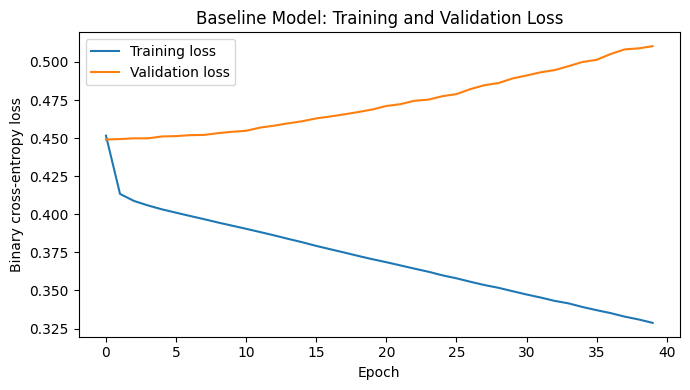

In [5]:
# 5. Build and train the baseline neural network
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_processed.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="baseline_churn_model")

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline_model.fit(
    X_train_processed, y_train,
    validation_split=0.20,
    epochs=40,
    batch_size=32,
    verbose=1
)

baseline_probabilities = baseline_model.predict(X_test_processed, verbose=0).ravel()
baseline_predictions = (baseline_probabilities >= 0.5).astype("int32")
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print(f"Baseline test accuracy: {baseline_accuracy:.4f}")

# Plot baseline training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(baseline_history.history["loss"], label="Training loss")
plt.plot(baseline_history.history["val_loss"], label="Validation loss")
plt.title("Baseline Model: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.show()


Epoch 1/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7393 - loss: 0.5905 - val_accuracy: 0.7853 - val_loss: 0.5229
Epoch 2/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7888 - loss: 0.5112 - val_accuracy: 0.7826 - val_loss: 0.5090
Epoch 3/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7992 - loss: 0.4892 - val_accuracy: 0.7844 - val_loss: 0.4983
Epoch 4/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8054 - loss: 0.4809 - val_accuracy: 0.7853 - val_loss: 0.4922
Epoch 5/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8012 - loss: 0.4732 - val_accuracy: 0.7853 - val_loss: 0.4868
Epoch 6/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8061 - loss: 0.4621 - val_accuracy: 0.7826 - val_loss: 0.4831
Epoch 7/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8045 - loss: 0.4578 - val_accuracy: 0.7879 - val_loss: 0.4780
Epoch 8/60
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8096 - loss: 0.4532 - val_accuracy: 0.

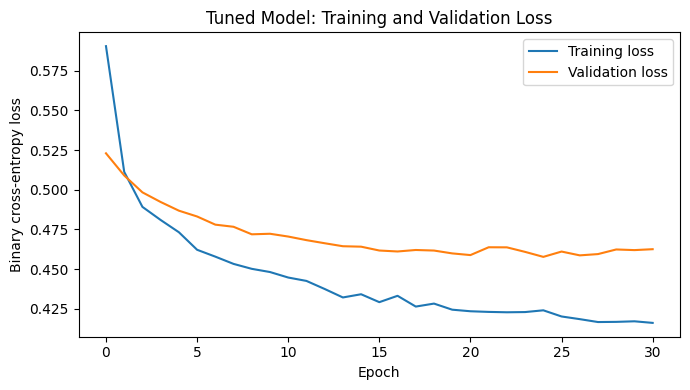

In [6]:
# 6. Tune the model with Dropout, L2 regularization, and Early Stopping
tuned_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_processed.shape[1],)),
    tf.keras.layers.Dense(
        64, activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.001)
    ),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(
        32, activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.001)
    ),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(1, activation="sigmoid")
], name="tuned_churn_model")

tuned_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)

tuned_history = tuned_model.fit(
    X_train_processed, y_train,
    validation_split=0.20,
    epochs=60,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

tuned_probabilities = tuned_model.predict(X_test_processed, verbose=0).ravel()
tuned_predictions = (tuned_probabilities >= 0.5).astype("int32")
tuned_accuracy = accuracy_score(y_test, tuned_predictions)
print(f"Tuned model test accuracy: {tuned_accuracy:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(tuned_history.history["loss"], label="Training loss")
plt.plot(tuned_history.history["val_loss"], label="Validation loss")
plt.title("Tuned Model: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.tight_layout()
plt.show()


,Model,Test accuracy
0,Baseline neural network,0.7686
1,Tuned neural network,0.7842


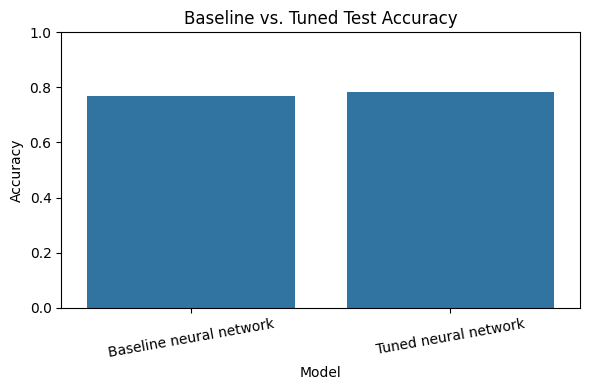

The tuned model achieved higher test accuracy on this run.


In [7]:
# 7. Compare baseline and tuned model accuracy
comparison = pd.DataFrame({
    "Model": ["Baseline neural network", "Tuned neural network"],
    "Test accuracy": [baseline_accuracy, tuned_accuracy]
})
display(comparison.style.format({"Test accuracy": "{:.4f}"}))

plt.figure(figsize=(6, 4))
sns.barplot(data=comparison, x="Model", y="Test accuracy")
plt.ylim(0, 1)
plt.title("Baseline vs. Tuned Test Accuracy")
plt.ylabel("Accuracy")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

if tuned_accuracy > baseline_accuracy:
    print("The tuned model achieved higher test accuracy on this run.")
elif tuned_accuracy < baseline_accuracy:
    print("The baseline model achieved higher test accuracy on this run; tuning did not improve accuracy for this split.")
else:
    print("Both models achieved the same test accuracy on this run.")


              precision    recall  f1-score   support

    No churn     0.8573    0.8473    0.8523      1035
       Churn     0.5907    0.6096    0.6000       374

    accuracy                         0.7842      1409
   macro avg     0.7240    0.7285    0.7261      1409
weighted avg     0.7865    0.7842    0.7853      1409

Test accuracy : 0.7842
Precision     : 0.5907
Recall        : 0.6096
F1-score      : 0.6000


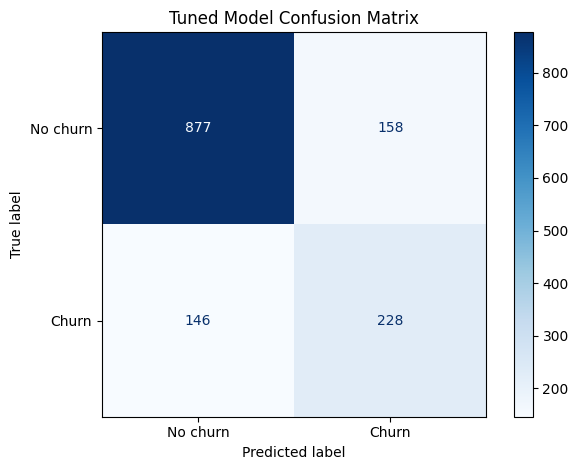

Accuracy alone can be misleading because the dataset contains more customers who do not churn than customers who do. Precision, recall, and F1-score help show how well the model identifies the smaller churn class and the trade-off between false positives and missed churners.


In [8]:
# 8. Evaluate the tuned model with precision, recall, F1-score, and confusion matrix
print(classification_report(
    y_test, tuned_predictions,
    labels=[0, 1],
    target_names=["No churn", "Churn"],
    digits=4,
    zero_division=0
))

precision = precision_score(y_test, tuned_predictions, zero_division=0)
recall = recall_score(y_test, tuned_predictions, zero_division=0)
f1 = f1_score(y_test, tuned_predictions, zero_division=0)

print(f"Test accuracy : {accuracy_score(y_test, tuned_predictions):.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1-score      : {f1:.4f}")

cm = confusion_matrix(y_test, tuned_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No churn", "Churn"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned Model Confusion Matrix")
plt.tight_layout()
plt.show()

print(
    "Accuracy alone can be misleading because the dataset contains more customers who do not churn than customers who do. "
    "Precision, recall, and F1-score help show how well the model identifies the smaller churn class and the trade-off between false positives and missed churners."
)


In [9]:
# 9. Save the tuned model and preprocessing object
MODEL_PATH = "best_customer_churn_model.keras"
PREPROCESSOR_PATH = "customer_churn_preprocessor.joblib"

tuned_model.save(MODEL_PATH)

# Saving preprocessing is necessary so new customers receive the same encoding and scaling.
import joblib
joblib.dump(preprocessor, PREPROCESSOR_PATH)

print("Saved model:", MODEL_PATH)
print("Saved preprocessing pipeline:", PREPROCESSOR_PATH)


Saved model: best_customer_churn_model.keras
Saved preprocessing pipeline: customer_churn_preprocessor.joblib


In [10]:
# 10. Load the saved model and predict for a hypothetical new customer
from tensorflow.keras.models import load_model

def predict_customer_churn(customer_details, model_path=MODEL_PATH, preprocessor_path=PREPROCESSOR_PATH):
    """Return the churn probability and predicted class for one new customer.

    customer_details should be a dictionary containing the original predictor columns,
    excluding customerID and Churn.
    """
    loaded_model = load_model(model_path)
    loaded_preprocessor = joblib.load(preprocessor_path)
    new_customer = pd.DataFrame([customer_details])
    new_customer = new_customer.drop(columns=["customerID", "Churn"], errors="ignore")
    transformed_customer = loaded_preprocessor.transform(new_customer).astype("float32")
    probability = float(loaded_model.predict(transformed_customer, verbose=0)[0][0])
    predicted_class = "Yes" if probability >= 0.5 else "No"
    return {"churn_probability": probability, "predicted_churn": predicted_class}

# Example customer values are hypothetical and are only used to demonstrate inference.
hypothetical_customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 75.0,
    "TotalCharges": 150.0
}

prediction = predict_customer_churn(hypothetical_customer)
print("Hypothetical customer prediction:")
print(f"Predicted churn: {prediction['predicted_churn']}")
print(f"Estimated churn probability: {prediction['churn_probability']:.2%}")


Hypothetical customer prediction:
Predicted churn: Yes
Estimated churn probability: 79.59%


## 11. Short answer: CNN vs. RNN
A **Convolutional Neural Network (CNN)** is useful when local patterns in grid-like data matter, such as identifying edges and objects in images. A **Recurrent Neural Network (RNN)** is designed for sequential data where order and earlier values can influence later ones, such as forecasting demand from time-series measurements. For example, a CNN can classify whether an image contains a cat, while an RNN can model the sequence of words in a sentence or analyze sensor readings over time. A standard Dense network is a reasonable choice for this assignment because each customer is represented by a fixed set of tabular features.